# Aula 15 — Exercício Prático: classificando diabetes com quatro modelos

**Especialização em Ciência de Dados · Análise e Ciência de Dados · IFRN**

**Gabarito comentado** do exercício prático — tente resolver antes de olhar!

### O caso
O dataset *Pima Indians Diabetes* (também do **Kaggle**: https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database, arquivo `diabetes.csv`) traz **768 mulheres** de origem Pima, com 21 anos ou mais, e o resultado de um teste de diabetes (`Outcome`: 1 = diabetes). Pergunta: **a partir de medidas clínicas simples, os quatro modelos da aula conseguem identificar quem tem diabetes?**

Ao contrário do laboratório (tumores), aqui as classes **se sobrepõem bastante** — você vai ver como isso muda as métricas e a escolha do modelo.

> Fonte original: National Institute of Diabetes and Digestive and Kidney Diseases (EUA), via UCI Machine Learning. Registros anônimos. Exercício de aprendizado de máquina, não ferramenta de diagnóstico.

| Coluna | Descrição |
|---|---|
| `Pregnancies` | número de gestações |
| `Glucose` | glicose plasmática 2 h após teste oral de tolerância (mg/dL) |
| `BloodPressure` | pressão diastólica (mmHg) |
| `SkinThickness` | espessura da dobra cutânea do tríceps (mm) |
| `Insulin` | insulina sérica 2 h (μU/mL) |
| `BMI` | índice de massa corporal (kg/m²) |
| `DiabetesPedigreeFunction` | índice de histórico familiar de diabetes |
| `Age` | idade (anos) |
| **`Outcome`** | **alvo**: 1 = diabetes, 0 = não |

**Como usar:** em cada passo, complete as células marcadas com `# TODO` e confira com o **resultado esperado**. Use `random_state=42` sempre que houver sorteio — assim seus números batem com os esperados. O exercício é para **treino** e **não precisa ser entregue**; o gabarito comentado está em `Aula15_Exercicio_Gabarito.ipynb`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, confusion_matrix, ConfusionMatrixDisplay)

sns.set_theme(style="whitegrid", palette="colorblind")
SEMENTE = 42
CORES = {"Regressão logística": "#0173b2", "Árvore de decisão": "#de8f05",
         "Random forest": "#029e73", "KNN": "#cc78bc"}

## Passo 1 — Ler os dados e conhecer o alvo
Leia `dados/diabetes.csv`, mostre o formato e a proporção de cada classe de `Outcome`.

**Resultado esperado:** `(768, 9)`; 500 sem diabetes e 268 com diabetes → **34,9%** de positivos.

In [2]:
df = pd.read_csv("dados/diabetes.csv")
print(df.shape)
print(df["Outcome"].value_counts())
print(df["Outcome"].value_counts(normalize=True).round(3))

(768, 9)
Outcome
0    500
1    268
Name: count, dtype: int64
Outcome
0    0.651
1    0.349
Name: proportion, dtype: float64


## Passo 2 — Zeros que são, na verdade, valores faltantes
Glicose, pressão, dobra cutânea, insulina e IMC iguais a **0** são impossíveis: são medidas que não foram feitas. Conte os zeros dessas cinco colunas e troque-os por `NaN` (a imputação será feita **dentro do pipeline**, para não vazar informação do teste).

**Resultado esperado:** Glucose 5 · BloodPressure 35 · SkinThickness 227 · Insulin 374 · BMI 11.

In [3]:
colunas_zero = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
print((df[colunas_zero] == 0).sum())
df[colunas_zero] = df[colunas_zero].replace(0, np.nan)
print("\nfaltantes após a troca:", df.isna().sum().sum())

Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

faltantes após a troca: 652


## Passo 3 — X, y e divisão treino/teste
Separe `X` (8 atributos) e `y` (`Outcome`). Divida com `test_size=0.25`, `stratify=y` e `random_state=SEMENTE`.

**Resultado esperado:** treino `(576, 8)`, teste `(192, 8)`; 34,9% de positivos nos dois (67 no teste).

In [4]:
X = df.drop(columns="Outcome")
y = df["Outcome"]
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEMENTE)
print(X_treino.shape, X_teste.shape)
print(f"positivos — treino: {y_treino.mean():.3f} | teste: {y_teste.mean():.3f} ({y_teste.sum()} casos)")

(576, 8) (192, 8)
positivos — treino: 0.349 | teste: 0.349 (67 casos)


## Passo 4 — Baseline
Treine um `DummyClassifier(strategy="most_frequent")` e calcule acurácia e recall no teste.

**Resultado esperado:** acurácia **0,651**, recall **0,000**.

In [5]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_treino, y_treino)
pred_dummy = dummy.predict(X_teste)
print(f"acurácia: {accuracy_score(y_teste, pred_dummy):.3f} | recall: {recall_score(y_teste, pred_dummy):.3f}")

acurácia: 0.651 | recall: 0.000


## Passo 5 — Os quatro pipelines
Monte um dicionário `modelos` com os quatro classificadores. Todos começam com `SimpleImputer(strategy="median")`; **regressão logística e KNN** recebem também `StandardScaler`. Use:
* `LogisticRegression(max_iter=1000)`
* `DecisionTreeClassifier(max_depth=4, min_samples_leaf=10, random_state=SEMENTE)`
* `RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=SEMENTE)`
* `KNeighborsClassifier(n_neighbors=15)`

**Resultado esperado:** um dicionário com 4 pipelines (nada é impresso além dele).

In [6]:
imputar = lambda: ("imputar", SimpleImputer(strategy="median"))
modelos = {
    "Regressão logística": Pipeline([imputar(), ("padronizar", StandardScaler()),
                                     ("classificador", LogisticRegression(max_iter=1000))]),
    "Árvore de decisão": Pipeline([imputar(), ("classificador",
                                   DecisionTreeClassifier(max_depth=4, min_samples_leaf=10, random_state=SEMENTE))]),
    "Random forest": Pipeline([imputar(), ("classificador",
                               RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=SEMENTE, n_jobs=-1))]),
    "KNN": Pipeline([imputar(), ("padronizar", StandardScaler()),
                     ("classificador", KNeighborsClassifier(n_neighbors=15))]),
}
list(modelos)

['Regressão logística', 'Árvore de decisão', 'Random forest', 'KNN']

## Passo 6 — Comparação com validação cruzada
Use `StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)` e `cross_validate` com `scoring=["accuracy", "recall", "f1", "roc_auc"]`. Monte uma tabela com a média de cada métrica e o desvio-padrão da ROC-AUC.

**Resultado esperado (médias):**

| modelo | acurácia | recall | F1 | ROC-AUC |
|---|---|---|---|---|
| Regressão logística | 0,778 | 0,583 | 0,646 | 0,831 ± 0,023 |
| Árvore de decisão | 0,724 | 0,662 | 0,622 | 0,777 ± 0,050 |
| Random forest | 0,748 | 0,523 | 0,591 | 0,825 ± 0,021 |
| KNN | 0,778 | 0,587 | 0,646 | 0,831 ± 0,032 |

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)
linhas = []
for nome, modelo in modelos.items():
    r = cross_validate(modelo, X_treino, y_treino, cv=cv, scoring=["accuracy", "recall", "f1", "roc_auc"])
    linhas.append({"modelo": nome, "acurácia": r["test_accuracy"].mean(), "recall": r["test_recall"].mean(),
                   "F1": r["test_f1"].mean(), "ROC-AUC": r["test_roc_auc"].mean(),
                   "ROC-AUC (dp)": r["test_roc_auc"].std()})
pd.DataFrame(linhas).set_index("modelo").round(3)

,acurácia,recall,F1,ROC-AUC,ROC-AUC (dp)
modelo,,,,,
Regressão logística,0.778,0.583,0.646,0.831,0.023
Árvore de decisão,0.724,0.662,0.622,0.777,0.050
Random forest,0.748,0.523,0.591,0.825,0.021
KNN,0.778,0.587,0.646,0.831,0.032


## Passo 7 — Matrizes de confusão no teste
Treine os quatro modelos no treino completo e desenhe as quatro matrizes de confusão do teste lado a lado.

**Resultado esperado (VN, FP, FN, VP):** regressão logística (105, 20, 33, 34) · árvore (103, 22, 25, 42) · random forest (107, 18, 29, 38) · KNN (104, 21, 32, 35).

Regressão logística [105  20  33  34]
Árvore de decisão [103  22  25  42]


Random forest [107  18  29  38]
KNN [104  21  32  35]


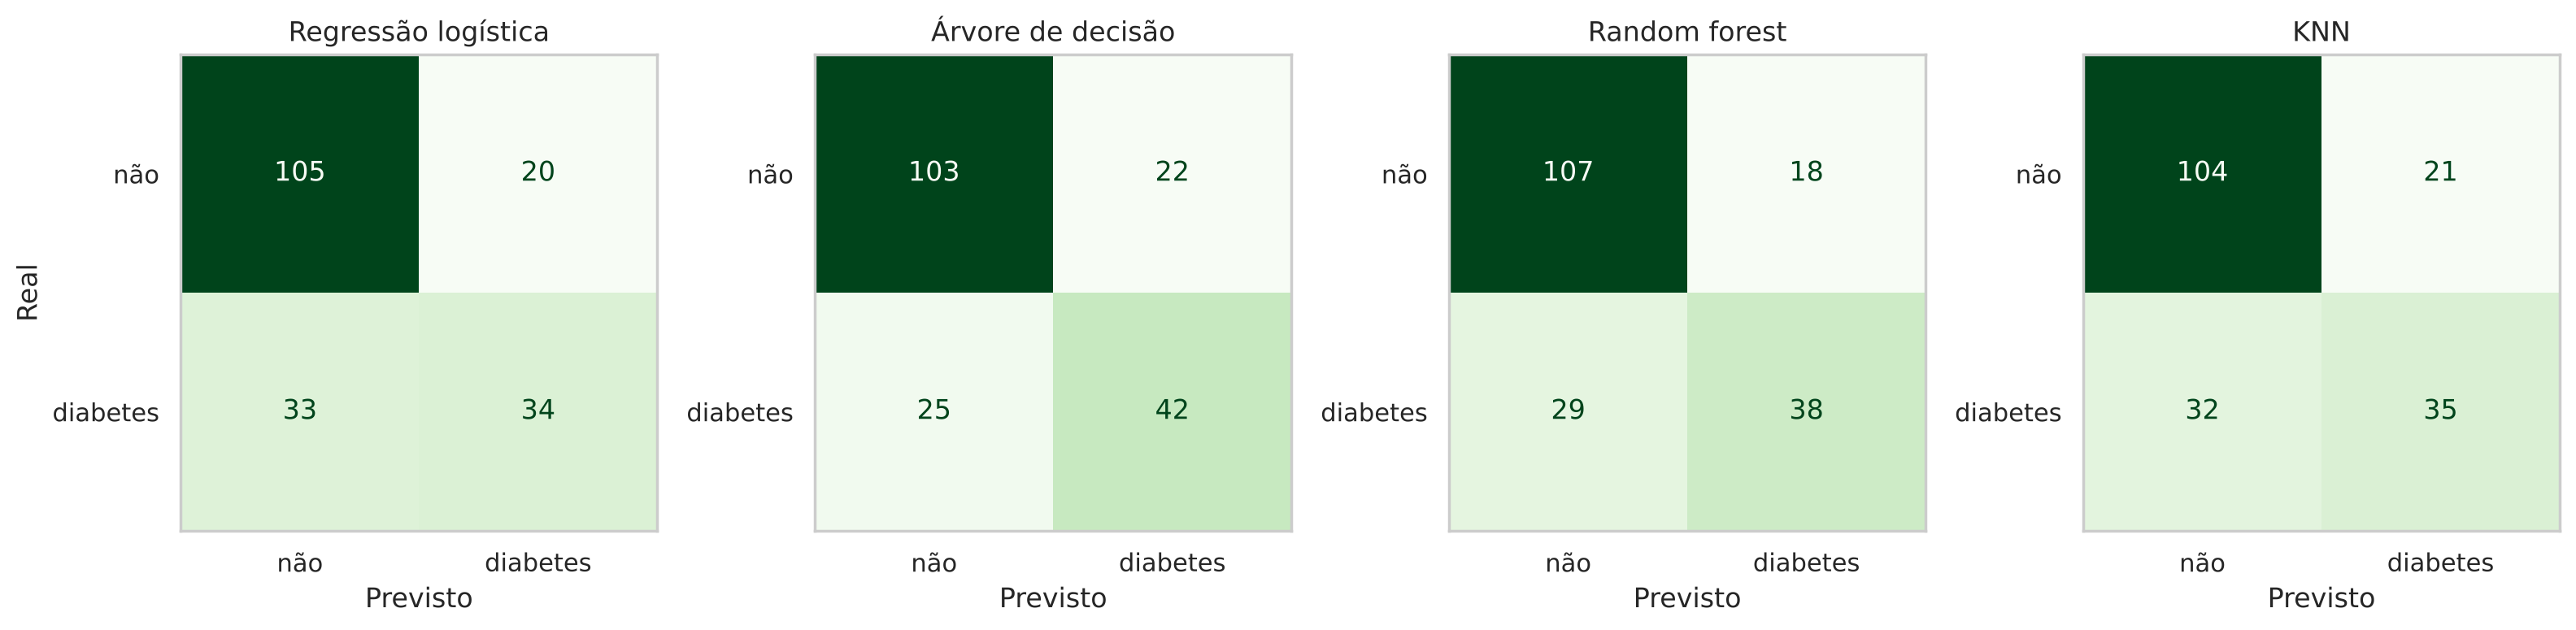

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.9))
for ax, (nome, modelo) in zip(axes, modelos.items()):
    modelo.fit(X_treino, y_treino)
    pred = modelo.predict(X_teste)
    ConfusionMatrixDisplay.from_predictions(y_teste, pred, display_labels=["não", "diabetes"],
                                            cmap="Greens", colorbar=False, ax=ax)
    ax.set(title=nome, xlabel="Previsto", ylabel="Real" if ax is axes[0] else ""); ax.grid(False)
    print(nome, confusion_matrix(y_teste, pred).ravel())
fig.tight_layout(); plt.show()

## Passo 8 — Curvas ROC
Desenhe as quatro curvas ROC do teste no mesmo gráfico, com a AUC na legenda.

**Resultado esperado (AUC no teste):** regressão logística 0,824 · árvore 0,781 · random forest 0,813 · KNN 0,800.

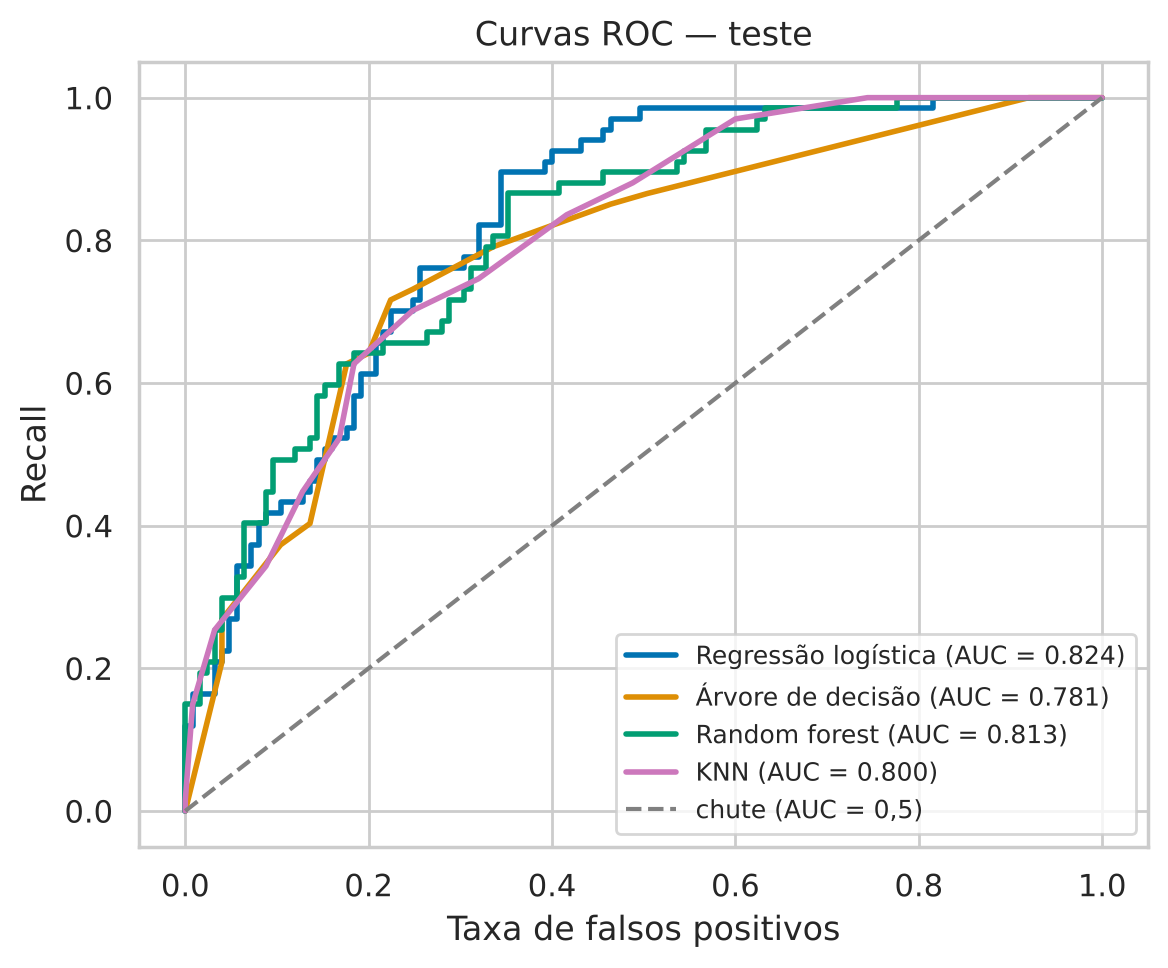

In [9]:
fig, ax = plt.subplots(figsize=(6, 5))
for nome, modelo in modelos.items():
    proba = modelo.predict_proba(X_teste)[:, 1]
    fpr, tpr, _ = roc_curve(y_teste, proba)
    ax.plot(fpr, tpr, lw=2, color=CORES[nome], label=f"{nome} (AUC = {roc_auc_score(y_teste, proba):.3f})")
ax.plot([0, 1], [0, 1], "--", color="gray", label="chute (AUC = 0,5)")
ax.set(title="Curvas ROC — teste", xlabel="Taxa de falsos positivos", ylabel="Recall")
ax.legend(loc="lower right", fontsize=9); fig.tight_layout(); plt.show()

## Passo 9 — Limiar para encontrar mais casos
Com a regressão logística, calcule recall, precisão, FN e FP para os limiares 0,2 · 0,3 · 0,4 · 0,5. Qual é o **maior** limiar com recall ≥ 0,75?

**Resultado esperado:** em 0,5: recall 0,507 (33 FN, 20 FP); em **0,3**: recall **0,776**, precisão 0,571 (15 FN, 39 FP); em 0,2: recall 0,896 (7 FN, 47 FP). Resposta: **0,3**.

In [10]:
proba = modelos["Regressão logística"].predict_proba(X_teste)[:, 1]
linhas = []
for limiar in [0.2, 0.3, 0.4, 0.5]:
    p = (proba >= limiar).astype(int)
    vn, fp, fn, vp = confusion_matrix(y_teste, p).ravel()
    linhas.append({"limiar": limiar, "recall": recall_score(y_teste, p),
                   "precisão": precision_score(y_teste, p), "FN": fn, "FP": fp})
pd.DataFrame(linhas).round(3).set_index("limiar")

,recall,precisão,FN,FP
limiar,,,,
0.2,0.896,0.561,7,47
0.3,0.776,0.571,15,39
0.4,0.612,0.621,26,25
0.5,0.507,0.630,33,20


## Passo 10 — Conclusão (resposta comentada)
**(a)** Regressão logística e KNN empatam na validação cruzada (acurácia 0,778, ROC-AUC 0,831); a **regressão logística** é preferível por ser mais simples, estável (desvio-padrão 0,023) e explicável — glicose e IMC são os atributos de maior peso. A árvore tem o maior recall na validação (0,662), mas a pior ROC-AUC e a maior variação entre os folds (± 0,050). No teste, árvore e floresta tiveram acurácia um pouco maior (0,755) — diferença pequena num teste de 192 pessoas, por isso a escolha é feita na **validação cruzada**.

**(b)** Aqui as classes **se sobrepõem**: muitas pessoas com e sem diabetes têm glicose, IMC e idade parecidos, e há muitos valores faltantes (insulina em quase metade). Nenhum modelo cria informação que não está nos dados — no laboratório, as medidas do núcleo separavam os tumores quase perfeitamente (ROC-AUC ≈ 0,99); aqui, ≈ 0,83.

**(c)** Numa triagem, perder um caso (FN) é pior que pedir um exame a mais (FP). Com limiar **0,3**, o modelo encontra 77,6% dos casos (52 de 67) em vez de 50,7%, ao custo de 39 falsos alarmes em vez de 20 (precisão 0,571).